# Taller 1 – Redes Neuronales Profundas (Perceptrón Multicapa)

**Suficiencia – Introducción al Aprendizaje Profundo**
**Estudiante:** Diego Alexander Valencia Calderón
**Dataset:** MNIST (dígitos manuscritos, 10 clases)

**Objetivo:** implementar, entrenar y evaluar un perceptrón multicapa (MLP) para clasificar dígitos manuscritos, alcanzando una exactitud (*accuracy*) mínima del 90 % sobre el conjunto de prueba.

| Sección | Requisito del enunciado |
|---|---|
| 1 | a) Preparación, análisis y procesamiento de train / validación / prueba |
| 2 | b) Construcción de la red neuronal profunda (MLP) |
| 3 | c) Compilación del modelo |
| 4 | d) Entrenamiento del modelo |
| 5 | e) Evaluación del desempeño |
| 6 | f) Generación de predicciones |
| 7 | g) Matriz de confusión e interpretación |
| 8 | h) Muestras clasificadas incorrectamente |
| 9 | Resumen de métricas |
| 10 | Análisis técnico y conclusiones |

**Salidas generadas**

| Archivo | Contenido |
|---|---|
| `figuras/01_distribucion_clases.png` | Distribución de clases por conjunto |
| `figuras/02_ejemplos_digitos.png` | Ejemplos de cada dígito |
| `figuras/03_curvas_entrenamiento.png` | Curvas de accuracy y loss (train vs. val) |
| `figuras/04_matriz_confusion.png` | Matriz de confusión en prueba |
| `figuras/05_muestras_mal_clasificadas.png` | Errores del modelo |
| `modelos/mlp_mnist_mejor.keras` | Mejor modelo según la pérdida de validación |
| `resultados/history_entrenamiento.csv` | Historial de entrenamiento por época |
| `resultados/classification_report.txt` | Precision, recall y F1 por clase |
| `resultados/metricas_taller1.json` | Resumen de métricas del taller |

## 0. Configuración del entorno

Detecta si el notebook corre en Colab o en local, define las rutas de salida, fija la semilla para reproducibilidad y verifica la GPU.

In [1]:
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = Path("/content/drive/MyDrive/Introducción al aprendizaje profundo/Suficiencia_Aprendizaje_Profundo")
else:
    REPO_DIR = Path.cwd().parent  # en local el notebook se ejecuta desde su propia carpeta

assert REPO_DIR.exists(), f"No se encontró el repositorio en {REPO_DIR}"

TALLER_DIR = REPO_DIR / "taller1_mlp"
FIG_DIR = TALLER_DIR / "figuras"
RES_DIR = TALLER_DIR / "resultados"
MOD_DIR = TALLER_DIR / "modelos"
for carpeta in (FIG_DIR, RES_DIR, MOD_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)  # fija las semillas de Python, NumPy y TensorFlow

print("Entorno:", "Google Colab" if EN_COLAB else "Local")
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "no disponible")
print("Repositorio:", REPO_DIR)

Entorno: Local
TensorFlow: 2.21.0
GPU: no disponible
Repositorio: d:\Universidad\ITM\Materias\Ingeniería de Sistemas\4. Introducción al aprendizaje profundo - Optativa III\Suficiencia_Aprendizaje_Profundo


## 1. Preparación, análisis y procesamiento de los datos (a)

### 1.1 Carga del dataset

MNIST contiene imágenes en escala de grises de 28 × 28 píxeles con dígitos manuscritos del 0 al 9. `keras.datasets.mnist.load_data()` lo descarga automáticamente y lo entrega dividido en 60.000 imágenes de entrenamiento y 10.000 de prueba.

Además de la semilla fijada en la configuración, se activa el determinismo de operaciones de TensorFlow para que el entrenamiento en GPU sea reproducible.

In [2]:
# Fuerza a TensorFlow a usar implementaciones deterministas (reproducibilidad también en GPU)
tf.config.experimental.enable_op_determinism()

(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Entrenamiento original:", x_train_full.shape, y_train_full.shape)
print("Prueba:                ", x_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Entrenamiento original: (60000, 28, 28) (60000,)
Prueba:                 (10000, 28, 28) (10000,)


### 1.2 Partición en entrenamiento, validación y prueba

MNIST no trae un conjunto de validación, así que se extrae del entrenamiento original:

| Conjunto | Origen | Tamaño | Uso |
|---|---|---|---|
| Entrenamiento | Train original | 50.000 | Ajustar los pesos |
| Validación | Train original | 10.000 | Monitorear el sobreajuste, *early stopping* y selección del mejor modelo |
| Prueba | Test original | 10.000 | Evaluación final; no se usa en ninguna decisión del entrenamiento |

La división es **estratificada** (conserva la proporción de cada dígito) y reproducible con la semilla 42.

In [3]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=10_000,
    stratify=y_train_full,
    random_state=SEMILLA,
)

# Resumen de los tres conjuntos
resumen_conjuntos = pd.DataFrame(
    [
        (nombre, x.shape, y.shape, x.dtype, x.min(), x.max())
        for nombre, x, y in [
            ("Entrenamiento", x_train, y_train),
            ("Validación", x_val, y_val),
            ("Prueba", x_test, y_test),
        ]
    ],
    columns=["Conjunto", "Forma X", "Forma y", "Tipo", "Mín. píxel", "Máx. píxel"],
)
display(resumen_conjuntos)

,Conjunto,Forma X,Forma y,Tipo,Mín. píxel,Máx. píxel
0,Entrenamiento,"(50000, 28, 28)","(50000,)",uint8,0,255
1,Validación,"(10000, 28, 28)","(10000,)",uint8,0,255
2,Prueba,"(10000, 28, 28)","(10000,)",uint8,0,255


### 1.3 Análisis exploratorio (EDA)

**Distribución de clases.** Se verifica si las 10 clases están balanceadas en los tres conjuntos. Un desbalance fuerte haría engañosa la *accuracy* global y obligaría a ponderar las clases.

,Entrenamiento,Validación,Prueba,Entrenamiento (%),Validación (%),Prueba (%)
Dígito,,,,,,
0,4936,987,980,9.87,9.87,9.80
1,5618,1124,1135,11.24,11.24,11.35
2,4965,993,1032,9.93,9.93,10.32
3,5109,1022,1010,10.22,10.22,10.10
4,4868,974,982,9.74,9.74,9.82
5,4518,903,892,9.04,9.03,8.92
6,4932,986,958,9.86,9.86,9.58
7,5221,1044,1028,10.44,10.44,10.28
8,4876,975,974,9.75,9.75,9.74


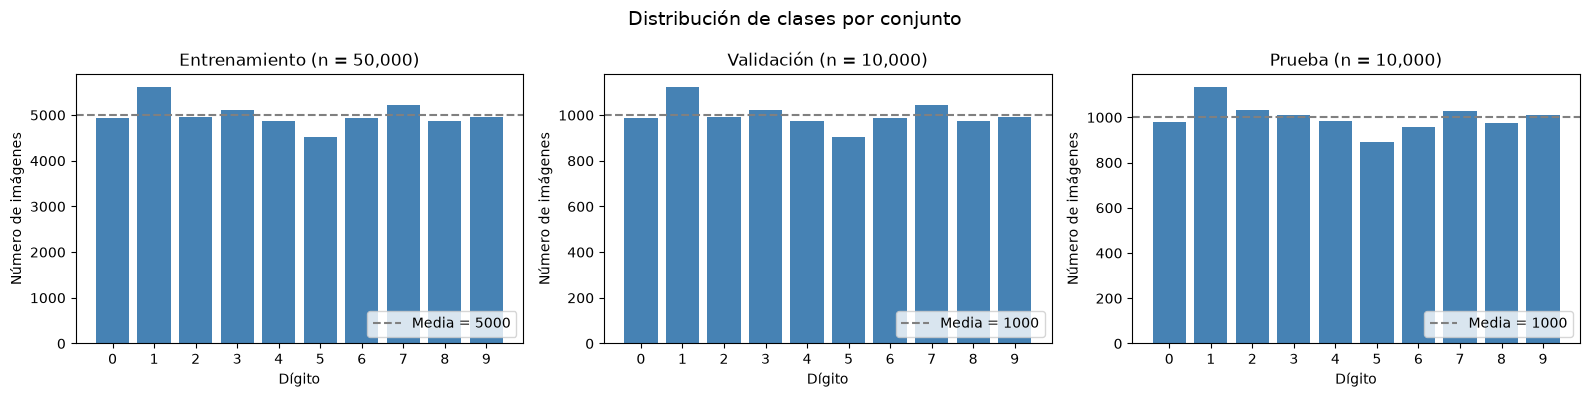

Razón clase mayoritaria / minoritaria por conjunto:
Entrenamiento    1.243
Validación       1.245
Prueba           1.272


In [4]:
CLASES = np.arange(10)

conteos = pd.DataFrame(
    {
        "Entrenamiento": np.bincount(y_train, minlength=10),
        "Validación": np.bincount(y_val, minlength=10),
        "Prueba": np.bincount(y_test, minlength=10),
    },
    index=pd.Index(CLASES, name="Dígito"),
)
porcentajes = (conteos / conteos.sum() * 100).round(2).add_suffix(" (%)")
display(pd.concat([conteos, porcentajes], axis=1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (nombre, serie) in zip(axes, conteos.items()):
    ax.bar(CLASES, serie.values, color="steelblue")
    ax.axhline(serie.mean(), color="gray", linestyle="--", label=f"Media = {serie.mean():.0f}")
    ax.set_title(f"{nombre} (n = {serie.sum():,})")
    ax.set_xlabel("Dígito")
    ax.set_ylabel("Número de imágenes")
    ax.set_xticks(CLASES)
    ax.legend(loc="lower right")
fig.suptitle("Distribución de clases por conjunto", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

razon = conteos.max() / conteos.min()
print("Razón clase mayoritaria / minoritaria por conjunto:")
print(razon.round(3).to_string())

Las clases están aproximadamente balanceadas: la clase más frecuente (el 1) tiene alrededor de 1,25 veces las muestras de la menos frecuente (el 5), como confirma la razón impresa arriba, y la estratificación conserva esa proporción en entrenamiento y validación. No es necesario ponderar las clases, y la *accuracy* es una métrica representativa para este problema.

**Ejemplos por dígito.** La grilla muestra la variabilidad de la escritura dentro de cada clase (grosor, inclinación y forma).

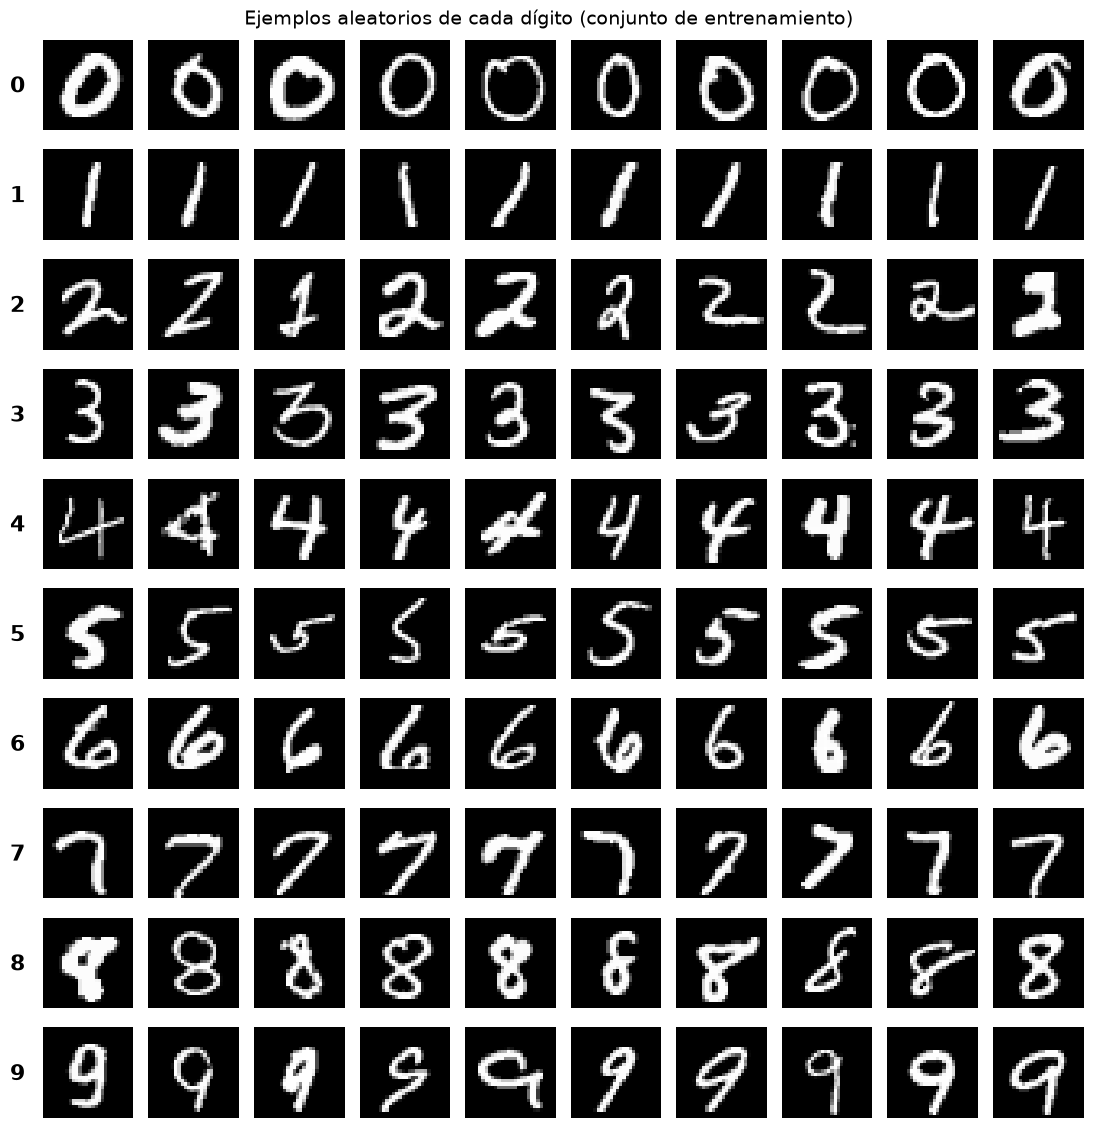

In [5]:
N_EJEMPLOS = 10
rng = np.random.default_rng(SEMILLA)

fig, axes = plt.subplots(10, N_EJEMPLOS, figsize=(N_EJEMPLOS * 1.1, 10 * 1.15))
for digito in CLASES:
    indices = rng.choice(np.where(y_train == digito)[0], N_EJEMPLOS, replace=False)
    for j, i in enumerate(indices):
        ax = axes[digito, j]
        ax.imshow(x_train[i], cmap="gray")
        ax.axis("off")
    axes[digito, 0].text(-6, 14, str(digito), fontsize=16, fontweight="bold", ha="right", va="center")
fig.suptitle("Ejemplos aleatorios de cada dígito (conjunto de entrenamiento)", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_ejemplos_digitos.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.4 Procesamiento

1. **Normalización a [0, 1]:** los píxeles vienen como enteros entre 0 y 255. Al dividir entre 255, las entradas quedan en una escala pequeña y homogénea, lo que estabiliza los gradientes y acelera la convergencia.
2. **Aplanado de 28 × 28 a 784:** un MLP solo recibe vectores, así que cada imagen se convierte en un vector de 784 características. Con esto se pierde la estructura espacial de la imagen, que es la principal limitación del MLP frente a una CNN.
3. **Codificación de etiquetas como enteros (0–9):** se mantienen como enteros y se usa la pérdida `sparse_categorical_crossentropy`, que calcula lo mismo que `categorical_crossentropy` con *one-hot* sin necesidad de materializar matrices de 10 columnas.

Las imágenes originales (`x_test`) se conservan sin aplanar para las visualizaciones de las secciones 7 y 8.

In [6]:
def preprocesar(imagenes):
    # Normaliza a [0, 1] y aplana cada imagen de 28x28 en un vector de 784
    return (imagenes.astype("float32") / 255.0).reshape(len(imagenes), -1)


X_train = preprocesar(x_train)
X_val = preprocesar(x_val)
X_test = preprocesar(x_test)

for nombre, X, y in [("Entrenamiento", X_train, y_train), ("Validación", X_val, y_val), ("Prueba", X_test, y_test)]:
    print(f"{nombre:<14} X: {X.shape}  rango [{X.min():.1f}, {X.max():.1f}]  y: {y.shape} {y.dtype}")

Entrenamiento  X: (50000, 784)  rango [0.0, 1.0]  y: (50000,) uint8
Validación     X: (10000, 784)  rango [0.0, 1.0]  y: (10000,) uint8
Prueba         X: (10000, 784)  rango [0.0, 1.0]  y: (10000,) uint8


## 2. Construcción de la red neuronal profunda – MLP (b)

| Capa | Neuronas | Activación | Justificación |
|---|---|---|---|
| Entrada | 784 | — | Un valor por píxel |
| Oculta 1 | 512 | ReLU | Capacidad suficiente para combinaciones de trazos |
| Dropout | — | 30 % | Regularización: evita co-adaptación de neuronas |
| Oculta 2 | 256 | ReLU | Representaciones más abstractas y compactas |
| Dropout | — | 30 % | Regularización |
| Oculta 3 | 128 | ReLU | Última representación antes de clasificar |
| Dropout | — | 20 % | Regularización más suave cerca de la salida |
| Salida | 10 | Softmax | Distribución de probabilidad sobre los 10 dígitos |

- **ReLU** evita el desvanecimiento del gradiente que sufren sigmoide y tanh en redes profundas y es barata de calcular.
- La arquitectura **piramidal** (512 → 256 → 128) comprime progresivamente la información hacia la decisión final.
- **Dropout** apaga aleatoriamente un porcentaje de neuronas en cada paso de entrenamiento. Es necesario porque el modelo tiene más de medio millón de parámetros frente a 50.000 imágenes y, sin regularización, tiende a memorizar el entrenamiento.

In [7]:
N_ENTRADAS = X_train.shape[1]  # 784
N_CLASES = len(CLASES)  # 10


def construir_mlp():
    return keras.Sequential(
        [
            keras.Input(shape=(N_ENTRADAS,), name="entrada"),
            keras.layers.Dense(512, activation="relu", name="oculta_1"),
            keras.layers.Dropout(0.3, name="dropout_1"),
            keras.layers.Dense(256, activation="relu", name="oculta_2"),
            keras.layers.Dropout(0.3, name="dropout_2"),
            keras.layers.Dense(128, activation="relu", name="oculta_3"),
            keras.layers.Dropout(0.2, name="dropout_3"),
            keras.layers.Dense(N_CLASES, activation="softmax", name="salida"),
        ],
        name="mlp_mnist",
    )


modelo = construir_mlp()
modelo.summary()

Model: "mlp_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

El número de parámetros de cada capa densa es `entradas × neuronas + sesgos`. Por ejemplo, la primera capa tiene 784 × 512 + 512 = 401.920 parámetros, y concentra la mayor parte del modelo. Las capas Dropout no tienen parámetros.

## 3. Compilación del modelo (c)

| Elemento | Elección | Justificación |
|---|---|---|
| Optimizador | Adam, tasa de aprendizaje 0,001 | Ajusta una tasa de aprendizaje adaptativa por parámetro y combina *momentum*; converge rápido y es robusto con sus valores por defecto |
| Pérdida | `SparseCategoricalCrossentropy` | Clasificación multiclase con salida *softmax* y etiquetas enteras |
| Métrica | `accuracy` | Las clases están balanceadas y es la métrica exigida por el enunciado |

In [8]:
TASA_APRENDIZAJE = 1e-3

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=TASA_APRENDIZAJE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

## 4. Entrenamiento del modelo (d)

- **Épocas máximas:** 30. Es un techo; el entrenamiento real lo decide *early stopping*.
- **Tamaño del batch:** 128. Equilibra la estabilidad del gradiente con el número de actualizaciones por época (391 pasos por época).
- **EarlyStopping:** detiene el entrenamiento si la pérdida de validación no mejora durante 5 épocas consecutivas y restaura los mejores pesos.
- **ModelCheckpoint:** guarda en `modelos/mlp_mnist_mejor.keras` el modelo con la menor pérdida de validación.

Se monitorea `val_loss` en lugar de `val_accuracy` porque la pérdida es más sensible: refleja también la confianza de las predicciones, y empieza a subir antes que la *accuracy* cuando aparece el sobreajuste.

In [9]:
EPOCAS = 30
TAMANO_BATCH = 128
PACIENCIA = 5
RUTA_MEJOR_MODELO = MOD_DIR / "mlp_mnist_mejor.keras"

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PACIENCIA, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        str(RUTA_MEJOR_MODELO), monitor="val_loss", save_best_only=True, verbose=1
    ),
]

history = modelo.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCAS,
    batch_size=TAMANO_BATCH,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/30

Epoch 1: val_loss improved from None to 0.14316, saving model to d:\Universidad\ITM\Materias\Ingeniería de Sistemas\4. Introducción al aprendizaje profundo - Optativa III\Suficiencia_Aprendizaje_Profundo\taller1_mlp\modelos\mlp_mnist_mejor.keras

Epoch 1: finished saving model to d:\Universidad\ITM\Materias\Ingeniería de Sistemas\4. Introducción al aprendizaje profundo - Optativa III\Suficiencia_Aprendizaje_Profundo\taller1_mlp\modelos\mlp_mnist_mejor.keras
391/391 - 10s - 26ms/step - accuracy: 0.8896 - loss: 0.3623 - val_accuracy: 0.9564 - val_loss: 0.1432
Epoch 2/30

Epoch 2: val_loss improved from 0.14316 to 0.11895, saving model to d:\Universidad\ITM\Materias\Ingeniería de Sistemas\4. Introducción al aprendizaje profundo - Optativa III\Suficiencia_Aprendizaje_Profundo\taller1_mlp\modelos\mlp_mnist_mejor.keras

Epoch 2: finished saving model to d:\Universidad\ITM\Materias\Ingeniería de Sistemas\4. Introducción al aprendizaje profundo - Optativa III\Suficiencia_Aprendizaj

El historial se guarda en `resultados/history_entrenamiento.csv` y luego se carga el mejor modelo desde el *checkpoint*. Así, todas las evaluaciones siguientes usan exactamente el modelo guardado en disco, y la evaluación se puede reproducir sin reentrenar.

In [10]:
historial = pd.DataFrame(history.history)
historial.index = pd.RangeIndex(1, len(historial) + 1, name="época")
historial.to_csv(RES_DIR / "history_entrenamiento.csv")

EPOCAS_ENTRENADAS = len(historial)
MEJOR_EPOCA = int(historial["val_loss"].idxmin())
print(f"Épocas entrenadas: {EPOCAS_ENTRENADAS} | Mejor época (mínima val_loss): {MEJOR_EPOCA}")
display(historial.round(4))

modelo = keras.models.load_model(RUTA_MEJOR_MODELO)
print("Mejor modelo cargado desde:", RUTA_MEJOR_MODELO)

Épocas entrenadas: 12 | Mejor época (mínima val_loss): 7


,accuracy,loss,val_accuracy,val_loss
época,,,,
1,0.8896,0.3623,0.9564,0.1432
2,0.9549,0.1480,0.9627,0.1189
3,0.9664,0.1111,0.9756,0.0882
4,0.9720,0.0896,0.9763,0.0810
5,0.9770,0.0770,0.9778,0.0790
6,0.9796,0.0655,0.9759,0.0899
7,0.9817,0.0595,0.9807,0.0737
8,0.9836,0.0521,0.9786,0.0912
9,0.9842,0.0506,0.9804,0.0751


Mejor modelo cargado desde: d:\Universidad\ITM\Materias\Ingeniería de Sistemas\4. Introducción al aprendizaje profundo - Optativa III\Suficiencia_Aprendizaje_Profundo\taller1_mlp\modelos\mlp_mnist_mejor.keras


## 5. Evaluación del desempeño (e)

El modelo se evalúa sobre los tres conjuntos. La métrica oficial es la del conjunto de **prueba**, que el modelo no vio durante el entrenamiento ni se usó para elegir el mejor modelo. Comparar los tres conjuntos permite detectar sobreajuste: una brecha grande entre entrenamiento y prueba indicaría memorización.

In [11]:
META_ACCURACY = 0.90

evaluacion = pd.DataFrame(
    [
        (nombre, *modelo.evaluate(X, y, batch_size=TAMANO_BATCH, verbose=0))
        for nombre, X, y in [
            ("Entrenamiento", X_train, y_train),
            ("Validación", X_val, y_val),
            ("Prueba", X_test, y_test),
        ]
    ],
    columns=["Conjunto", "Loss", "Accuracy"],
).set_index("Conjunto")
display(evaluacion.round(4))

test_loss, test_accuracy = evaluacion.loc["Prueba", ["Loss", "Accuracy"]]
print(f"\nAccuracy en prueba: {test_accuracy:.4f} ({test_accuracy:.2%})")
print(f"Meta exigida:       {META_ACCURACY:.2%} -> {'CUMPLE' if test_accuracy >= META_ACCURACY else 'NO CUMPLE'}")

,Loss,Accuracy
Conjunto,,
Entrenamiento,0.0223,0.9927
Validación,0.0737,0.9807
Prueba,0.0754,0.9803



Accuracy en prueba: 0.9803 (98.03%)
Meta exigida:       90.00% -> CUMPLE


### Curvas de entrenamiento

Durante el entrenamiento, Keras calcula las métricas de *train* con Dropout activo, mientras que en validación Dropout se desactiva. Por eso es normal que, en las primeras épocas, la curva de validación aparezca **por encima** de la de entrenamiento en *accuracy* (y por debajo en *loss*) sin que eso sea un error.

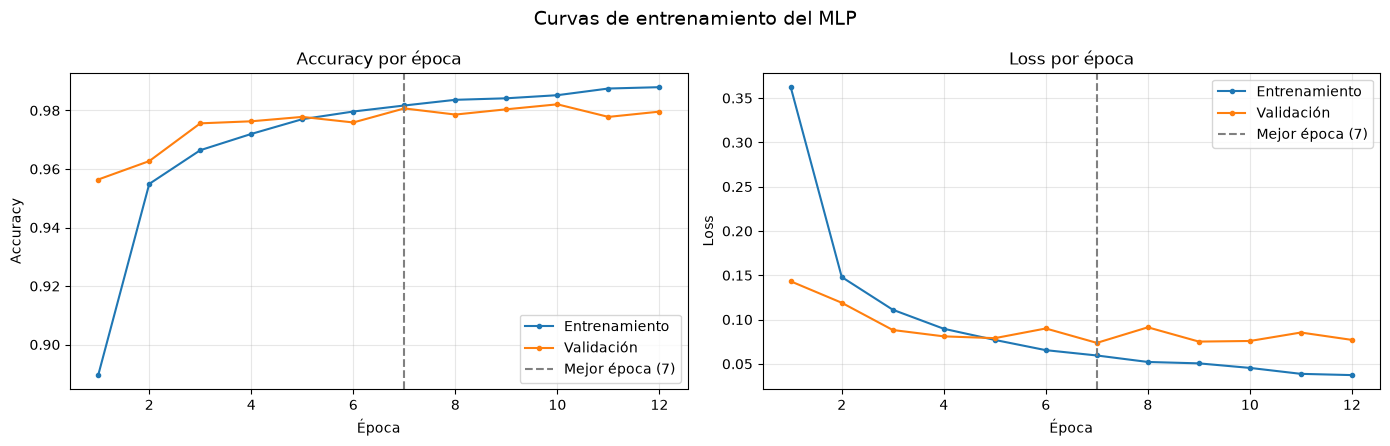

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metrica, titulo in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(historial.index, historial[metrica], marker="o", markersize=3, label="Entrenamiento")
    ax.plot(historial.index, historial[f"val_{metrica}"], marker="o", markersize=3, label="Validación")
    ax.axvline(MEJOR_EPOCA, color="gray", linestyle="--", label=f"Mejor época ({MEJOR_EPOCA})")
    ax.set_title(f"{titulo} por época")
    ax.set_xlabel("Época")
    ax.set_ylabel(titulo)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Curvas de entrenamiento del MLP", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Generación de predicciones (f)

La capa *softmax* entrega, para cada imagen, 10 probabilidades que suman 1. La clase predicha es la de mayor probabilidad (`argmax`) y esa probabilidad máxima se interpreta como la **confianza** del modelo.

In [13]:
probabilidades = modelo.predict(X_test, batch_size=TAMANO_BATCH, verbose=0)
y_pred = probabilidades.argmax(axis=1)
confianza = probabilidades.max(axis=1)

# Comprobación: la accuracy calculada a mano debe coincidir con la de evaluate()
print(f"Accuracy a partir de las predicciones: {(y_pred == y_test).mean():.4f}")

muestra = pd.DataFrame(
    {
        "Real": y_test[:15],
        "Predicho": y_pred[:15],
        "Confianza": confianza[:15].round(4),
        "Correcto": y_pred[:15] == y_test[:15],
    }
)
display(muestra)

Accuracy a partir de las predicciones: 0.9803


,Real,Predicho,Confianza,Correcto
0,7,7,1.0000,True
1,2,2,1.0000,True
2,1,1,1.0000,True
3,0,0,1.0000,True
4,4,4,0.9998,True
5,1,1,1.0000,True
6,4,4,0.9999,True
7,9,9,0.9999,True
8,5,5,0.7021,True
9,9,9,0.9999,True


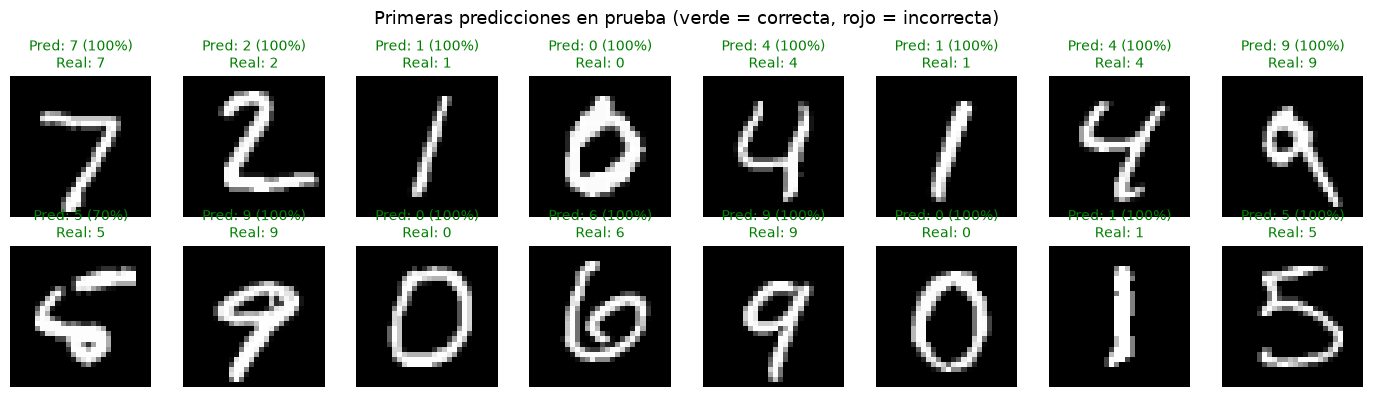

In [14]:
# Visualización de las primeras predicciones sobre el conjunto de prueba
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i], cmap="gray")
    color = "green" if y_pred[i] == y_test[i] else "red"
    ax.set_title(f"Pred: {y_pred[i]} ({confianza[i]:.0%})\nReal: {y_test[i]}", color=color, fontsize=10)
    ax.axis("off")
fig.suptitle("Primeras predicciones en prueba (verde = correcta, rojo = incorrecta)", fontsize=13)
fig.tight_layout()
plt.show()

## 7. Matriz de confusión e interpretación (g)

Las filas son la clase **real** y las columnas la clase **predicha**. La diagonal cuenta los aciertos y cada celda fuera de ella cuenta un tipo concreto de error (por ejemplo, fila 4 y columna 9: cuatros clasificados como nueves).

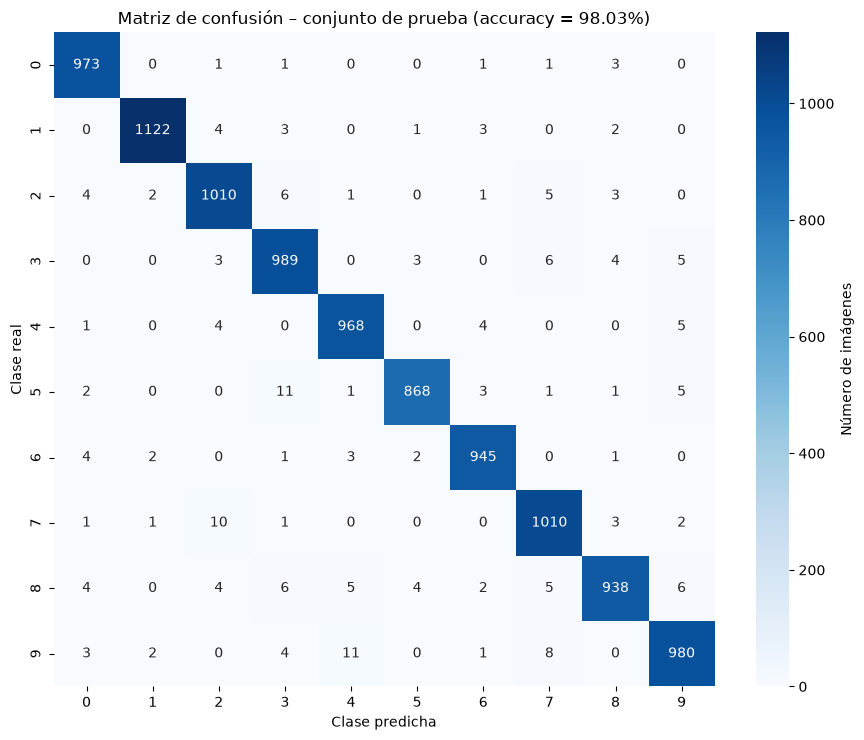

In [15]:
from sklearn.metrics import classification_report, confusion_matrix

matriz = confusion_matrix(y_test, y_pred, labels=CLASES)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASES,
    yticklabels=CLASES,
    cbar_kws={"label": "Número de imágenes"},
    ax=ax,
)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión – conjunto de prueba (accuracy = {test_accuracy:.2%})")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

### Reporte de clasificación

- **Precision:** de las imágenes que el modelo etiquetó como el dígito *k*, qué fracción realmente era *k*.
- **Recall:** de las imágenes que realmente eran *k*, qué fracción reconoció el modelo.
- **F1:** media armónica de las dos anteriores.

In [16]:
reporte = classification_report(
    y_test, y_pred, labels=CLASES, target_names=[str(c) for c in CLASES], digits=4
)
print(reporte)
(RES_DIR / "classification_report.txt").write_text(
    "Taller 1 – MLP sobre MNIST: reporte de clasificación (conjunto de prueba)\n\n" + reporte,
    encoding="utf-8",
)

              precision    recall  f1-score   support

           0     0.9808    0.9929    0.9868       980
           1     0.9938    0.9885    0.9912      1135
           2     0.9749    0.9787    0.9768      1032
           3     0.9677    0.9792    0.9734      1010
           4     0.9788    0.9857    0.9822       982
           5     0.9886    0.9731    0.9808       892
           6     0.9844    0.9864    0.9854       958
           7     0.9749    0.9825    0.9787      1028
           8     0.9822    0.9630    0.9725       974
           9     0.9771    0.9713    0.9742      1009

    accuracy                         0.9803     10000
   macro avg     0.9803    0.9801    0.9802     10000
weighted avg     0.9803    0.9803    0.9803     10000



833

### Confusiones más frecuentes

Para no depender de una lectura visual de la matriz, se extraen las parejas (real → predicho) con más errores y la tasa de error de cada dígito.

In [17]:
errores_matriz = matriz.copy()
np.fill_diagonal(errores_matriz, 0)

pares_confundidos = (
    pd.DataFrame(
        [(real, pred, errores_matriz[real, pred]) for real in CLASES for pred in CLASES if errores_matriz[real, pred] > 0],
        columns=["Real", "Predicho", "Errores"],
    )
    .sort_values("Errores", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
print("Las 10 confusiones más frecuentes:")
display(pares_confundidos)

errores_por_clase = pd.DataFrame(
    {
        "Muestras": matriz.sum(axis=1),
        "Aciertos": np.diag(matriz),
        "Errores": matriz.sum(axis=1) - np.diag(matriz),
    },
    index=pd.Index(CLASES, name="Dígito real"),
)
errores_por_clase["Tasa de error (%)"] = (errores_por_clase["Errores"] / errores_por_clase["Muestras"] * 100).round(2)
print("Errores por dígito real (ordenados de mayor a menor tasa de error):")
display(errores_por_clase.sort_values("Tasa de error (%)", ascending=False))

Las 10 confusiones más frecuentes:


,Real,Predicho,Errores
0,5,3,11
1,9,4,11
2,7,2,10
3,9,7,8
4,2,3,6
5,8,3,6
6,8,9,6
7,3,7,6
8,4,9,5
9,2,7,5


Errores por dígito real (ordenados de mayor a menor tasa de error):


,Muestras,Aciertos,Errores,Tasa de error (%)
Dígito real,,,,
8,974,938,36,3.70
9,1009,980,29,2.87
5,892,868,24,2.69
2,1032,1010,22,2.13
3,1010,989,21,2.08
7,1028,1010,18,1.75
4,982,968,14,1.43
6,958,945,13,1.36
1,1135,1122,13,1.15


### Interpretación

- **La diagonal domina la matriz.** La gran mayoría de las imágenes de cada dígito se clasifica correctamente, y los errores aparecen como valores pequeños dispersos fuera de la diagonal.
- **Los errores se concentran en dígitos con trazos parecidos.** Las tablas anteriores identifican las parejas concretas. En MNIST, las confusiones típicas de un MLP son **4 ↔ 9** (el 4 con la parte superior cerrada se parece a un 9), **3 ↔ 5** y **5 ↔ 6** (comparten la curva inferior), **7 ↔ 2** y **7 ↔ 9**, y el **8** con varios dígitos, porque comparte trazos con el 3, el 5 y el 9.
- **El 0 y el 1 suelen ser los dígitos más fáciles.** Tienen formas muy distintivas (un óvalo cerrado y un trazo vertical), lo que se refleja en su alta precision y recall.
- **Las confusiones no son simétricas.** Que muchos 4 se predigan como 9 no implica que muchos 9 se predigan como 4. La matriz revela la dirección del error, algo que la *accuracy* global oculta.

## 8. Muestras clasificadas incorrectamente (h)

Se identifican las imágenes donde la predicción no coincide con la etiqueta real (`y_pred != y_test`). Se muestran las 25 en las que el modelo se equivocó **con mayor confianza**, porque son las más informativas: revelan si el modelo falla por dígitos realmente ambiguos o por una debilidad propia.

Imágenes mal clasificadas: 197 de 10000 (1.97%)


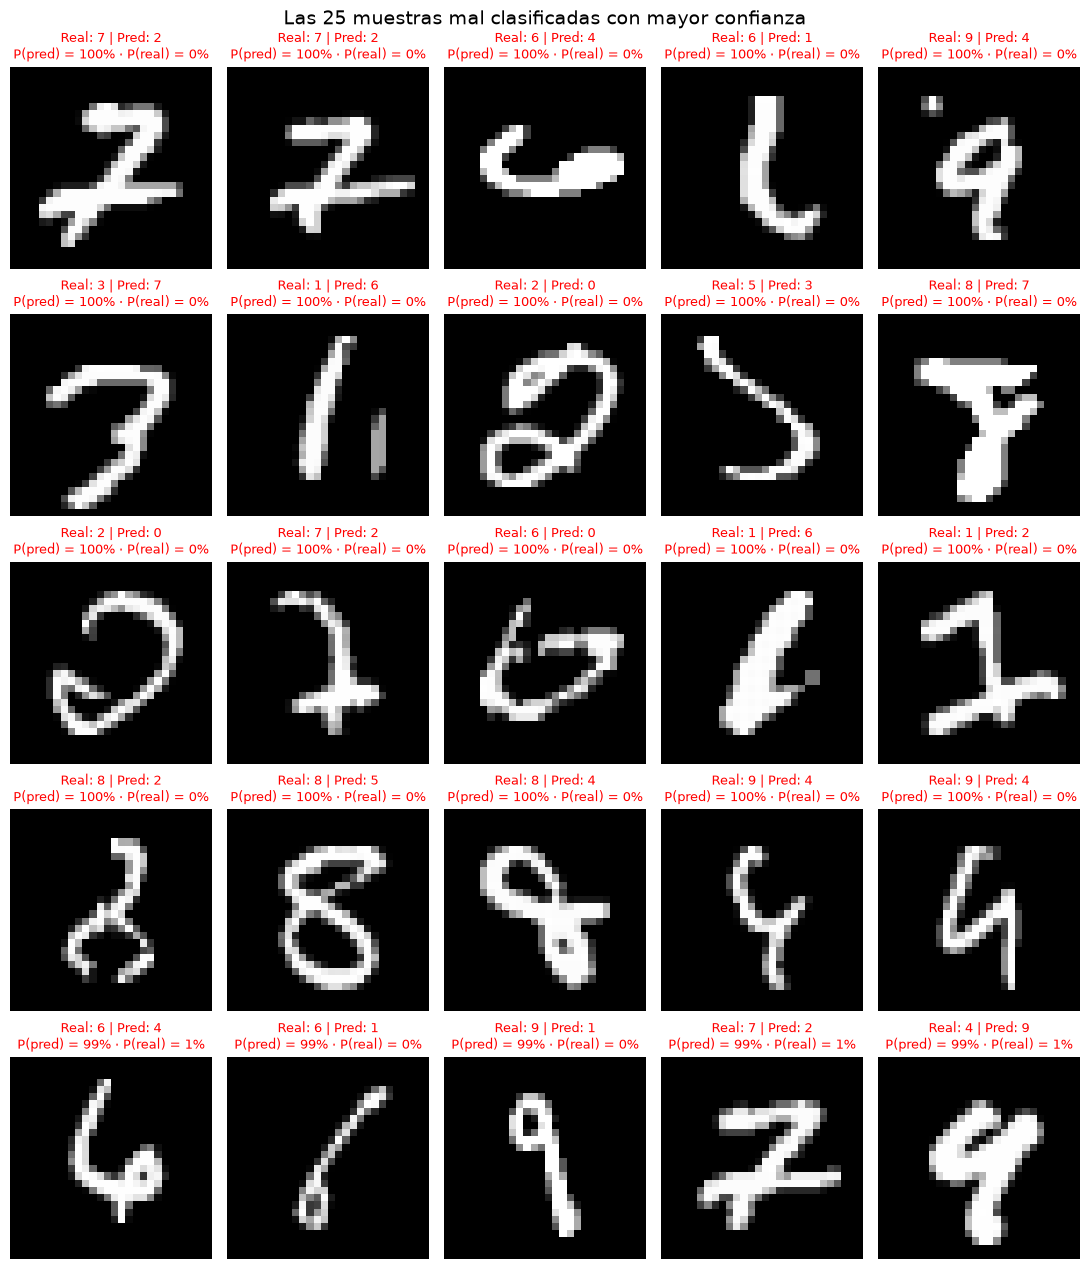

In [18]:
indices_errores = np.where(y_pred != y_test)[0]
print(f"Imágenes mal clasificadas: {len(indices_errores)} de {len(y_test)} ({len(indices_errores) / len(y_test):.2%})")

# Ordena los errores de mayor a menor confianza en la predicción equivocada
errores_ordenados = indices_errores[np.argsort(-confianza[indices_errores])]
N_MOSTRAR = min(25, len(errores_ordenados))

fig, axes = plt.subplots(5, 5, figsize=(11, 13))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, errores_ordenados[:N_MOSTRAR]):
    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(
        f"Real: {y_test[i]} | Pred: {y_pred[i]}\n"
        f"P(pred) = {confianza[i]:.0%} · P(real) = {probabilidades[i, y_test[i]]:.0%}",
        color="red",
        fontsize=9,
    )
fig.suptitle(f"Las {N_MOSTRAR} muestras mal clasificadas con mayor confianza", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_muestras_mal_clasificadas.png", dpi=150, bbox_inches="tight")
plt.show()

**Cómo leer la grilla.** `P(pred)` es la probabilidad que el modelo asignó a la clase equivocada y `P(real)` la que asignó a la correcta.

- Si `P(real)` es casi 0 %, el modelo estaba convencido de su error. Suele ocurrir con dígitos escritos de forma muy atípica o incluso mal etiquetados en el dataset.
- Si `P(real)` es considerable, el modelo dudaba entre ambas clases y la imagen es genuinamente ambigua.

Muchas de estas imágenes resultan difíciles incluso para una persona: trazos incompletos, dígitos girados o descentrados, o formas que realmente se parecen a la clase predicha.

## 9. Resumen de métricas

Se exporta un resumen del experimento a `resultados/metricas_taller1.json`.

In [19]:
import json

metricas = {
    "dataset": "MNIST",
    "conjuntos": {
        "entrenamiento": int(len(y_train)),
        "validacion": int(len(y_val)),
        "prueba": int(len(y_test)),
    },
    "arquitectura": "MLP 784-512-256-128-10 (ReLU + Dropout 0.3/0.3/0.2, salida softmax)",
    "num_parametros": int(modelo.count_params()),
    "hiperparametros": {
        "optimizador": "Adam",
        "tasa_aprendizaje": TASA_APRENDIZAJE,
        "perdida": "sparse_categorical_crossentropy",
        "batch_size": TAMANO_BATCH,
        "epocas_maximas": EPOCAS,
        "paciencia_early_stopping": PACIENCIA,
        "semilla": SEMILLA,
    },
    "epocas_entrenadas": EPOCAS_ENTRENADAS,
    "mejor_epoca": MEJOR_EPOCA,
    "train_accuracy": float(evaluacion.loc["Entrenamiento", "Accuracy"]),
    "val_accuracy": float(evaluacion.loc["Validación", "Accuracy"]),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "errores_prueba": int(len(indices_errores)),
    "meta_accuracy": META_ACCURACY,
    "cumple_meta": bool(test_accuracy >= META_ACCURACY),
}

(RES_DIR / "metricas_taller1.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metricas, ensure_ascii=False, indent=2))

{
  "dataset": "MNIST",
  "conjuntos": {
    "entrenamiento": 50000,
    "validacion": 10000,
    "prueba": 10000
  },
  "arquitectura": "MLP 784-512-256-128-10 (ReLU + Dropout 0.3/0.3/0.2, salida softmax)",
  "num_parametros": 567434,
  "hiperparametros": {
    "optimizador": "Adam",
    "tasa_aprendizaje": 0.001,
    "perdida": "sparse_categorical_crossentropy",
    "batch_size": 128,
    "epocas_maximas": 30,
    "paciencia_early_stopping": 5,
    "semilla": 42
  },
  "epocas_entrenadas": 12,
  "mejor_epoca": 7,
  "train_accuracy": 0.9926999807357788,
  "val_accuracy": 0.9807000160217285,
  "test_loss": 0.07540952414274216,
  "test_accuracy": 0.9803000092506409,
  "errores_prueba": 197,
  "meta_accuracy": 0.9,
  "cumple_meta": true
}


## 10. Análisis técnico y conclusiones

### Desempeño frente a la meta

El MLP supera con amplitud el 90 % de *accuracy* exigido sobre el conjunto de prueba; el valor exacto está en la sección 9. La *accuracy* de prueba es muy cercana a la de validación, lo que confirma que el conjunto de validación fue un buen estimador del desempeño real y que seleccionar el modelo con él no introdujo un sesgo apreciable.

### Comportamiento del entrenamiento

- Las curvas muestran una convergencia rápida: la mayor parte de la mejora ocurre en las primeras épocas, porque MNIST es un problema relativamente sencillo para una red con más de medio millón de parámetros.
- Dropout mantiene acotada la brecha entre entrenamiento y validación. Cuando la pérdida de validación deja de mejorar, *early stopping* detiene el entrenamiento y el *checkpoint* conserva la mejor época, evitando entregar un modelo sobreajustado.

### Lectura de la matriz de confusión y de los errores

- Los errores son pocos y se concentran en pares de dígitos con trazos similares (sección 7), no en una clase que el modelo no haya aprendido.
- Las muestras mal clasificadas (sección 8) son en buena parte dígitos ambiguos o atípicos, lo que indica que una parte del error residual es irreducible para cualquier modelo entrenado solo con estas etiquetas.

### Limitaciones

1. **Pérdida de la estructura espacial.** Al aplanar la imagen, el MLP trata cada píxel como una característica independiente: no sabe que dos píxeles son vecinos.
2. **Falta de invariancia a traslaciones.** Un mismo trazo desplazado unos píxeles activa entradas completamente distintas. El MLP debe aprender cada posición por separado, lo que explica parte de los errores con dígitos descentrados o inclinados.
3. **Muchos parámetros para la tarea.** La primera capa concentra la mayoría de los pesos. Una CNN alcanza mejores resultados con muchos menos parámetros gracias al **compartimiento de pesos**.
4. **Dataset muy controlado.** MNIST tiene dígitos centrados, normalizados en tamaño y sobre fondo limpio. El desempeño no se trasladaría directamente a fotografías de escritura real.

### Posibles mejoras

- **Redes convolucionales (CNN):** explotan la estructura espacial y suelen superar el 99 % en MNIST. Es la evolución natural hacia el Taller 2.
- **Data augmentation** con pequeñas rotaciones, desplazamientos y zoom, para hacer el modelo robusto a variaciones de escritura.
- **Batch Normalization** y un **programa de tasa de aprendizaje** (por ejemplo, `ReduceLROnPlateau`) para afinar la convergencia.
- **Búsqueda de hiperparámetros** (número de neuronas, tasas de Dropout y tasa de aprendizaje) con herramientas como KerasTuner.

### Conclusión

Un perceptrón multicapa con regularización por Dropout, entrenado con Adam y controlado con *early stopping*, resuelve la clasificación de MNIST por encima de la meta exigida. Al mismo tiempo, sus errores y limitaciones muestran por qué las arquitecturas convolucionales son la elección adecuada para datos con estructura espacial como las imágenes.